<!-- File automatically generated using DocOnce (https://github.com/doconce/doconce/):
doconce format ipynb 40.samkoding-notebook.do.txt --userdef_environment_file=../userdef_environments.py --skip_inline_comments --encoding=utf-8 --language=Norwegian --ipynb_disable_mpl_inline --execute=abort --output=../../pub/40/40.samkoding.ipynb --execute -->

# BIOS1101 H26 Samkoding

Date: **Uke 40**

# Samkoding uke 40

Til studentene: dette er 'oppskriften' til samkodingsgruppe denne uken.
Undervisere bruker denne noen ganger nøyaktig når de underviser,
noen ganger avviker de fra den.
Stoffet i notebooken ansees å være en del av pensum.

Vi legger disse notebooks ut til dere for at dere kan studere stoffet på egenhånd,
eventuelt sammen med opptak av gruppetimene.

Dette er en Jupyter Notebook, som betyr at all kode kan kjøres av dere,
men i tillegg kan dere legge til kodeceller for å skrive deres egen kode.
Brukt på denne måten kan det føre til økt læring!

------

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* Ukens samkoding
* Det sentrale dogmet med Python

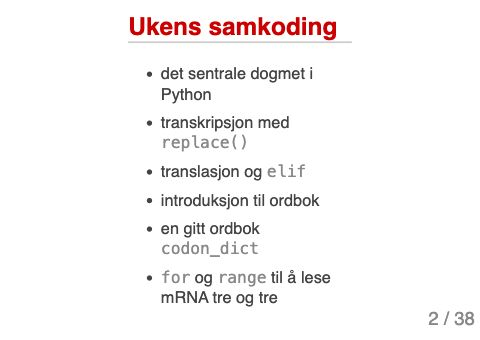

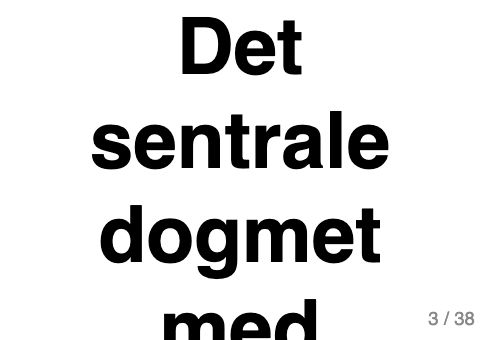

</div>

<div class="alert alert-block alert-info">
Vi begynner med noen slides for å illustrere ting vi trenger underveis.
</div>

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* DNA - RNA - protein
* Det sentrale dogmet
* Ukens mini-prosjekt
* Ukens mini-prosjekt
* Ukens mini-prosjekt
* Ukens mini-prosjekt
* Steg 1: DNA - RNA (transkripsjon)
* Steg 1: DNA - RNA (transkripsjon)

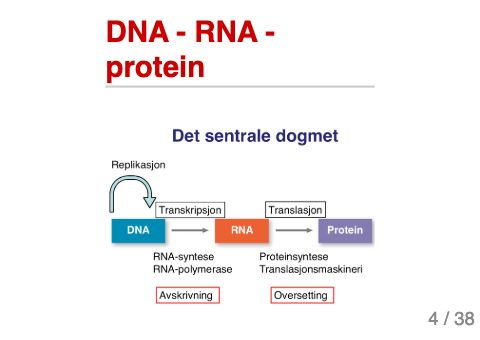

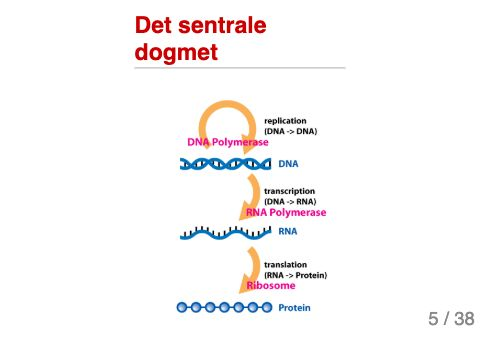

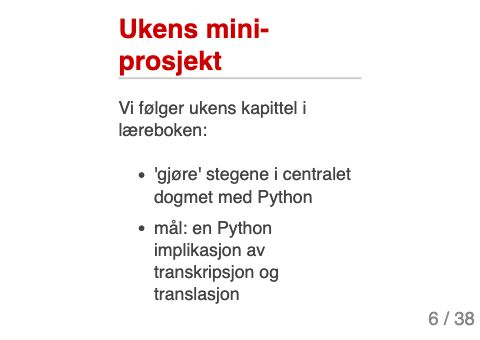

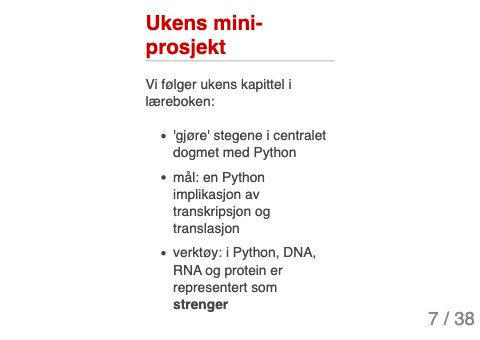

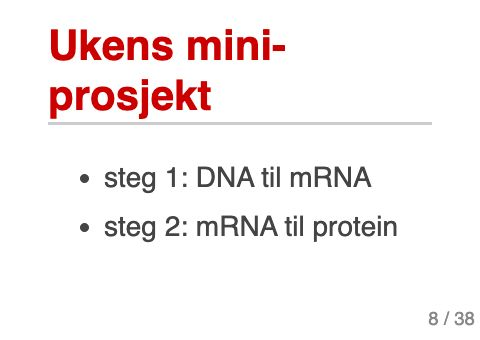

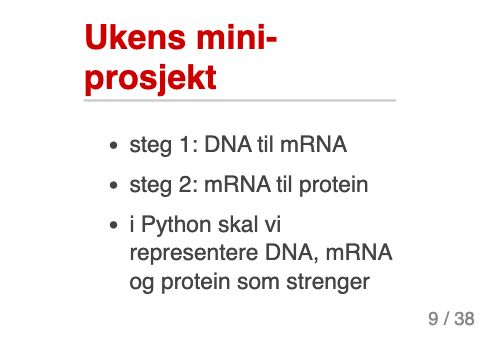

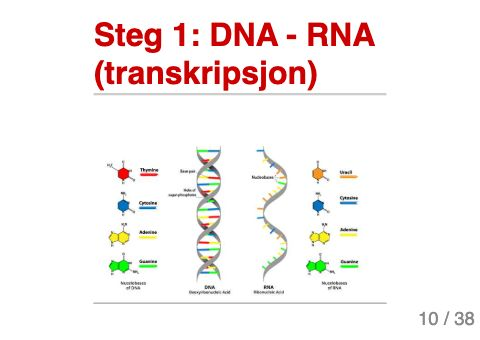

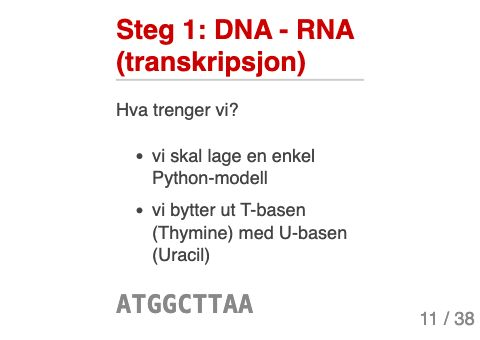

</div>

Vi starter med det første steget i det sentrale dogmet:
transkripsjon fra DNA til mRNA.

I denne samkodingen lager vi en enkel Python-modell.
Vi ser altså bort fra mye biologi og fokuserer på ett hovedpoeng:
i RNA bruker vi `U` der DNA bruker `T`.

In [2]:
dna = "ATGGCTTAA"
mrna = dna.replace("T", "U")
print(mrna)

AUGGCUUAA


Forrige uke var det en oppgave der målet var å endre en (del) av en streng.
Forskjellen med denne oppgaven er at `str.replace()` bytter ut *alle* forekomster.

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* Steg 1: DNA - RNA (transkripsjon)
* Steg 2: RNA - protein (translasjon)
* Kodon hjulet
* RNA - protein i Python

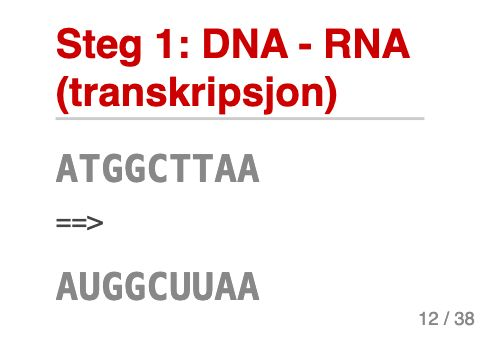

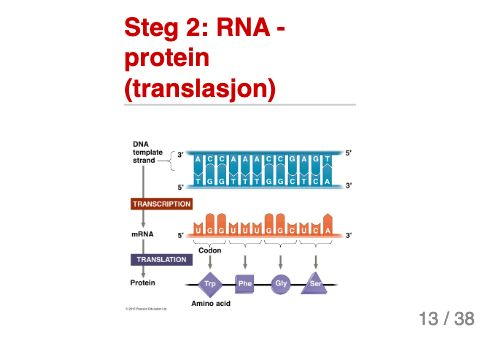

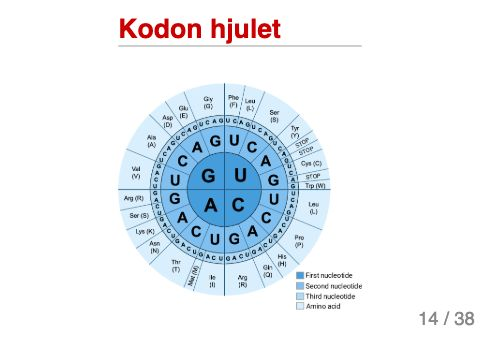

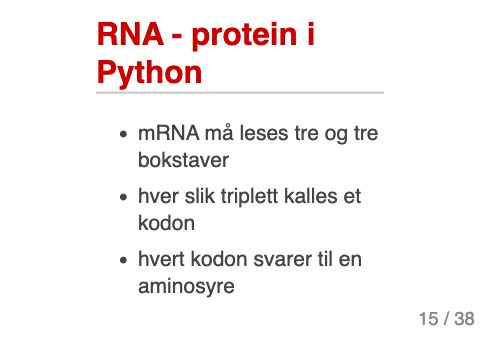

</div>

Neste steg er translasjon.
Da holder det ikke lenger å bare bruke `replace()`.

Vi må lese mRNA-strengen i biter på tre bokstaver,
for eksempel `"UUU"`, `"UUC"` og `"UCC"`.
Hver slik bit kalles et *kodon*.

For å få dette til trenger vi en måte å gå gjennom flere elementer på i Python.

Vi har tidligere brukt `while`-løkker.
Da må vi selv passe på å lage og oppdatere en indeksvariabel.

In [3]:
dna_sekvenser = ["ATGC", "ATGCTA", "AT", "ATGCGCTA"]

indeks = 0
while indeks < len(dna_sekvenser):
    sekvens = dna_sekvenser[indeks]
    lengde = len(sekvens)
    print(f"{sekvens} har lengde {lengde}.")
    indeks = indeks + 1

ATGC har lengde 4.
ATGCTA har lengde 6.
AT har lengde 2.
ATGCGCTA har lengde 8.


Men i Python finnes det også *for løkker*.
Her er et eksempel som gjør det samme:

In [4]:
dna_sekvenser = ["ATGC", "ATGCTA", "AT", "ATGCGCTA"]

for sekvens in dna_sekvenser:
    lengde = len(sekvens)
    print(f"{sekvens} har lengde {lengde}.")

ATGC har lengde 4.
ATGCTA har lengde 6.
AT har lengde 2.
ATGCGCTA har lengde 8.


Legg merke til:
* løkken starter med `for` og slutter med kolon `:`
* løkkevariabelen `term` får ett element om gangen
* vi trenger ikke å oppdatere løkkevariabelen selv
* `for` går over en *samling av elementer*

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* while og for løkker: forskjeller
* for løkker: struktur
* for løkker: flowchart
* while og for løkker

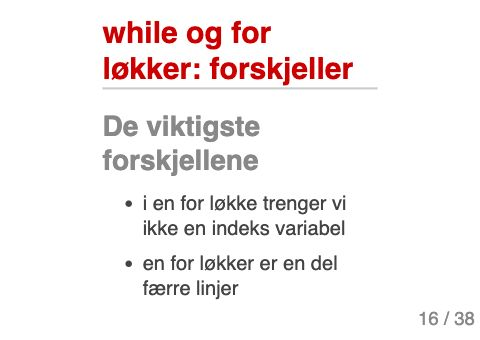

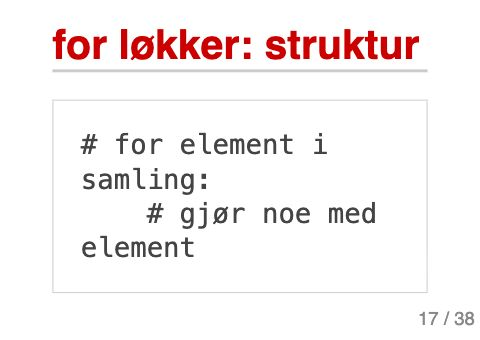

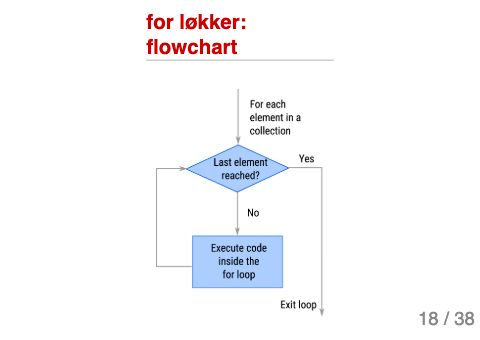

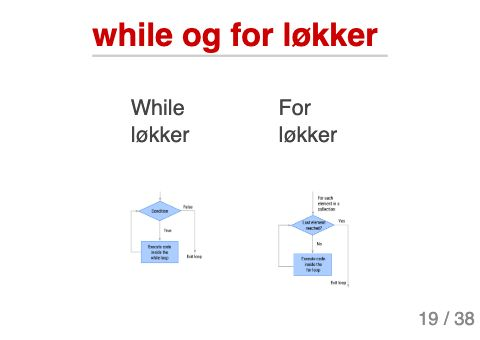

</div>

En liste er en samling av elementer, men det er også en streng.
Vi kan derfor bruke `for` på mRNA-strengen vår:

In [5]:
mrna = "AUGGCUUAA"
for base in mrna:
    print(base)

A
U
G
G
C
U
U
A
A


<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* Oppgave: transkripsjon med for løkke

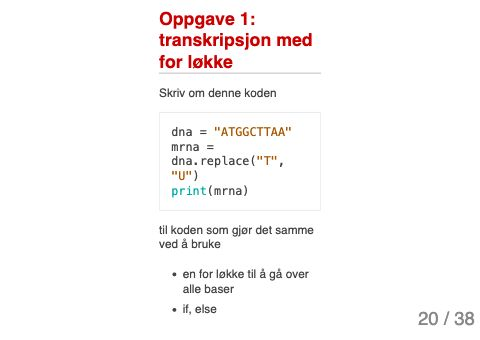

</div>

Men i translasjon trenger vi ikke én og én base.
Vi trenger tre og tre bokstaver om gangen.

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* mRNA må leses tre og tre bokstaver
* mRNA må leses tre og tre bokstaver

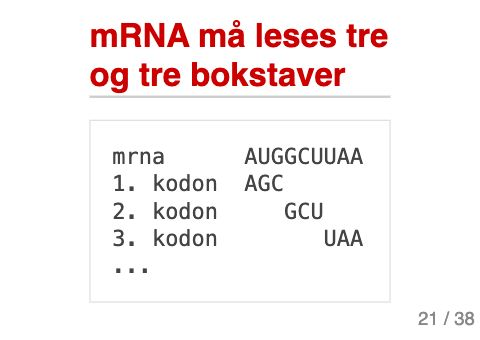

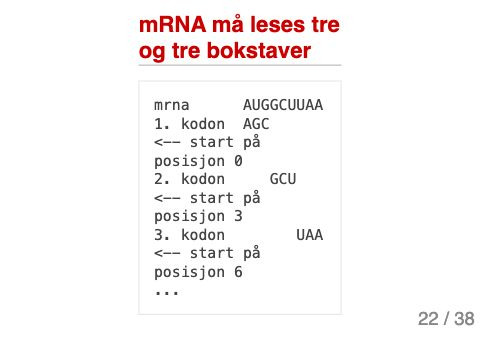

</div>

Her bruker vi `for` sammen med `range`.

In [6]:
mrna = "AUGGCUUAA"
for i in range(0, len(mrna), 3):
    print(f"Posisjon: {i}")

Posisjon: 0
Posisjon: 3
Posisjon: 6


Her blir posisjonene `0`, `3`, `6`, ...
Det passer godt fordi hvert kodon består av tre baser.

In [7]:
mrna = "AUGGCUUAA"
for i in range(0, len(mrna), 3):
    kodon = mrna[i:i+3]
    print(f"Posisjon: {i}, kodon: {kodon}")

Posisjon: 0, kodon: AUG
Posisjon: 3, kodon: GCU
Posisjon: 6, kodon: UAA


Ting å legge merke til:
* `range(0, len(mrna), 3)` lager posisjonene `0`, `3`, `6`, ...
* `mrna[i:i+3]` henter ut tre bokstaver av gangen
* dette passer godt fordi et kodon alltid er tre baser langt

Nå som vi får ett kodon om gangen, må vi bestemme
hvilken aminosyre dette kodonet tilsvarer.

<div class="alert alert-block alert-info">
Hvis igjen slide med kodon hjulet.
</div>

Vi kan gjøre dette med if-elif-else:

In [8]:
# kan bruke
if første_base == "U":
    if andre_base == "U":
        if tredje_base == "U" or tredje_base == "C":
            aminosyre == "F"
        else:
            aminosyre == "L"
    elif andre_base == "C":
            aminosyre == "L"
    elif andre_base == ...
    ...
elif ...

Vi utvider altså `if-else` med `elif`.

Egentlig er `elif` det samme some `else if`...

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* if-else
* if-elif-else

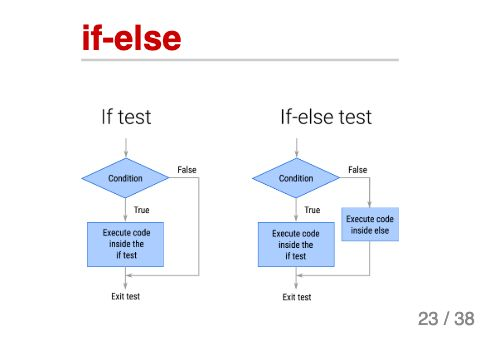

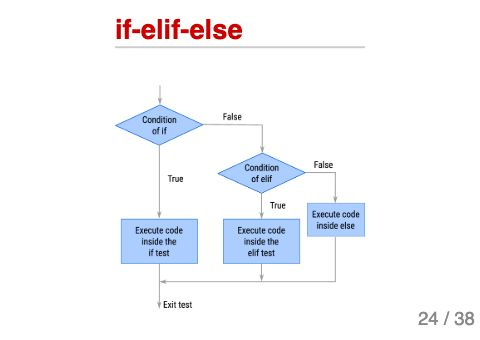

</div>

Dette fungerer for noen få kodoner.
Men i praksis blir det altfor mange linjer hvis vi skal gjøre dette
for alle kodonene i den genetiske koden.
I tillegg er det er lett å gjøre feil.

Hva om vi brukte lister?

In [8]:
# kan også bruke
kodoner = []
aminosyrer = []

kodoner.append("UUU")
aminosyrer.append("F")

kodoner.append("UUC")
aminosyrer.append("F")

kodoner.append("UUA")
aminosyrer.append("L")

kodoner.append("UUG")
aminosyrer.append("L")

kodoner.append("UCU")
aminosyrer.append("S")

kodoner.append("UCC")
aminosyrer.append("S")

kodoner.append("UCG")
aminosyrer.append("S")

kodoner.append("UCT")
aminosyrer.append("S")

Vi tar ikke med resten av kodonene.

In [9]:
print(kodoner)
print(aminosyrer)

['UUU', 'UUC', 'UUA', 'UUG', 'UCU', 'UCC', 'UCG', 'UCT']
['F', 'F', 'L', 'L', 'S', 'S', 'S', 'S']


Hvordan finne vi nå aminosyre som tilsvarer for eksempel kodonet `UCC`?
Vi trenger å finne indeksen til kodonet i listen `kodoner`,
og så hente ut aminosyren fra listen `aminosyrer` med denne indeksen.

Det er lettest når vi bruker en while løkke.

In [10]:
kodon = "UCC"
i = 0
while i < len(kodoner):
    print(kodoner[i], aminosyrer[i])
    i = i + 1

UUU F
UUC F
UUA L
UUG L
UCU S
UCC S
UCG S
UCT S


Nå skal vi finne kodonet:

In [11]:
kodon_vi_har = "UCC"
i = 0
while i < len(kodoner):
    if kodoner[i] == kodon_vi_har:
        print(aminosyrer[i])
    i = i + 1

S


Eller, med bedre bruk av while:

In [12]:
kodon_vi_har = "UCC"
i = 0
while kodoner[i] != kodon_vi_har:
    i = i + 1

print(aminosyrer[i])

S


Vi kan faktisk også skippe løkken hvis vi bruker `liste.index()`:

In [13]:
print(kodoner.index("UCC"))

5


Og så bruke indeksen for å finne aminosyren:

In [14]:
print(kodoner[5])

UCC


I et program:

In [15]:
indeks_vi_trenger = kodoner.index("UCC")
aminosyre = aminosyrer[indeks_vi_trenger]
print(aminosyre)

S


Denne løsningen fungerer, men er ikke så gunstig
når listen vi jobber med er veldig stor.

Den finnes faktisk en enklere måte å gjøre dette på.
Det vi trenger er er å bruke en såkalt **ordbok**.

En ordbok er en datastruktur der vi kobler en *nøkkel* til en *verdi*.
Vi kan tenke på det som et oppslagsverk.

In [16]:
aminosyrer = {
    "UUU": "F",
    "UUC": "F",
    "UCC": "S"
}

print(aminosyrer["UCC"])

S


Verdt å legge merke til:

* en ordbok starter med `{` og avsluttes med `}`
* en ordbok består av nøkkel-verdi-par
* kodonene er *nøkler*
* aminosyrene er *verdier*
* mellom nøkkel og verdi er det en kolon `:`
* mellom hvert nøkkel-verdi-par er det et komma

Et eksempel på bruken av ordbok

<div class="alert alert-block alert-info">
Samkodingen under er gjentatt på slides som kan vises etterpå for å oppsummere.
</div>

Vi setter opp en tom ordbok slik:

In [17]:
middager = {}

Vi kan også sette opp en ordbok med et par nøkkel-verdi-par med en gang:

In [18]:
middager = {
    "mandag": "suppe",
    "tirsdag": "spaghetti"
}
print(middager)

{'mandag': 'suppe', 'tirsdag': 'spaghetti'}


Vi ser at vi får hele ordboken tilbake på en linje.

For å legge til et nøkkel-verdi-par:

In [19]:
middager["onsdag"] = "pizza"
middager["torsdag"] = "fårikål"
print(middager)

{'mandag': 'suppe', 'tirsdag': 'spaghetti', 'onsdag': 'pizza', 'torsdag': 'fårikål'}


For å få ut verdien til en nøkkel i ordboken bruker vi dette:

In [20]:
print(middager["tirsdag"])

spaghetti


Ofte ønsker vi å gå over alle nøkler i en ordbok.
Det kan gjøres med en while løkke, men det er komplisert.
Her er en for løkke mye lettere å bruke:

In [21]:
for ukedag in middager:
    dagens_middag = middager[ukedag]
    print(f"På {ukedag} spiser jeg {dagens_middag}")

På mandag spiser jeg suppe
På tirsdag spiser jeg spaghetti
På onsdag spiser jeg pizza
På torsdag spiser jeg fårikål


<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* Ordbok
* Ordbok
* Ordbok
* Ordbok
* Ordbok

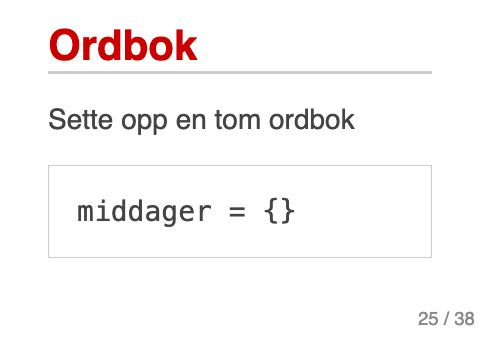

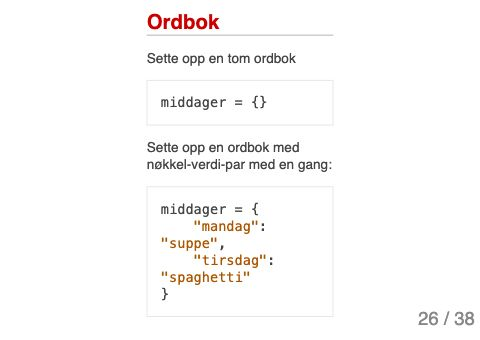

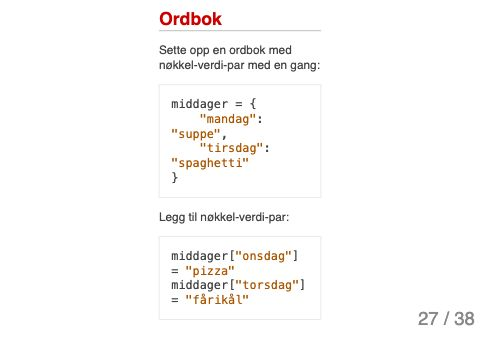

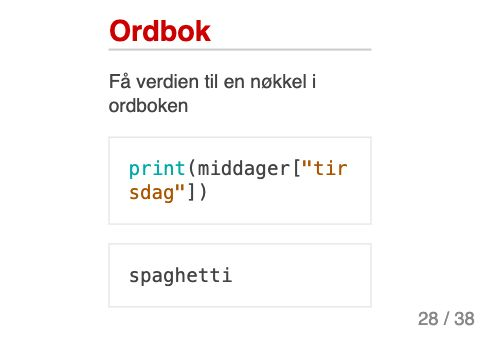

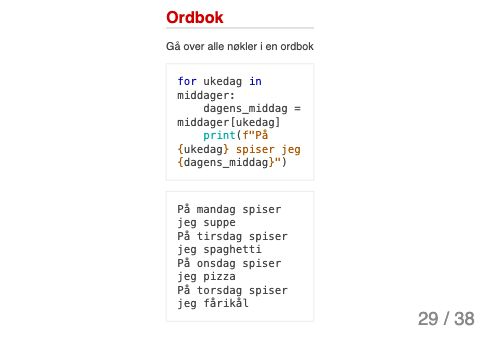

</div>

<div class="alert alert-block alert-info">
Vis den relevante delen om ordbok av 'cheat sheet' i Canvas.
Bruk det for å vise hvordan man setter opp en tom ordbok.
</div>

<div class="alert alert-block alert-info">
Bruk Python tutor for å gå gjennom koden under.
</div>

In [23]:
genetikk = ["gen", "kromosom", "dna", "transkript"]
min_term = genetikk[2]
tom_ordbok = {}
middager = {
    "mandag": "suppe",
    "tirsdag": "spaghetti"
}
middager["onsdag"] = "pizza"
middager["torsdag"] = "fårikål"
idag = "tirsdag"
dagens_middag = middager[idag]
for ukedag in middager:
    dagens_middag = middager[ukedag]
    print(f"På {ukedag} spiser jeg {dagens_middag}")

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* Lister og ordbok
* Oppgave: Navn og nummer

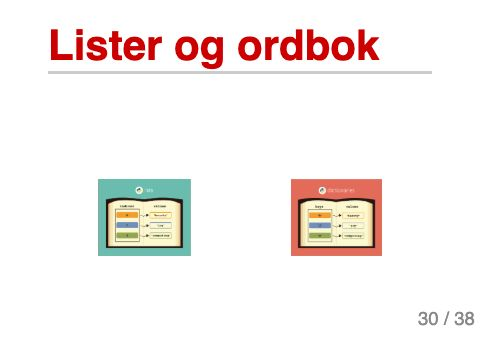

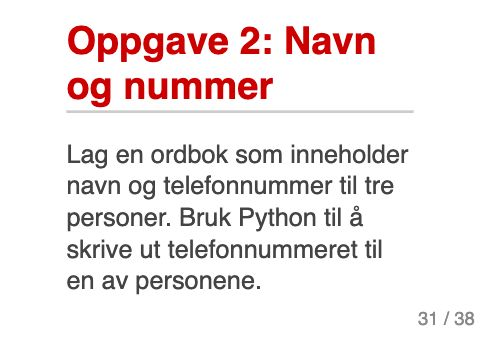

</div>

## RNA - protein i Python

Tilake til kodonene våre:

In [22]:
aminosyrer = {
    "UUU": "F",
    "UUC": "F",
    "UCC": "S"
}

print(aminosyrer["UCC"])

S


I en ordbok er kodonet nøkkelen,
og aminosyren er verdien vi vil hente ut.

In [23]:
kodon = "UCC"
aminosyre = aminosyrer[kodon]
print(aminosyre)

S


Vi trenger å ha en ordbok som har med alle 64 kodoner.
Den skal vi ikke kode selv men lese fra en fil:

**The code below can be loaded into a codecell with** `%load code/codon_dict.py`

In [24]:
codon_dict = {
    "UUU": "F", "UUC": "F", "UUA": "L", "UUG": "L",
    "UCU": "S", "UCC": "S", "UCA": "S", "UCG": "S",
    "UAU": "Y", "UAC": "Y", "UAA": "*", "UAG": "*",
    "UGU": "C", "UGC": "C", "UGA": "*", "UGG": "W",
    "CUU": "L", "CUC": "L", "CUA": "L", "CUG": "L",
    "CCU": "P", "CCC": "P", "CCA": "P", "CCG": "P",
    "CAU": "H", "CAC": "H", "CAA": "Q", "CAG": "Q",
    "CGU": "R", "CGC": "R", "CGA": "R", "CGG": "R",
    "AUU": "I", "AUC": "I", "AUA": "I", "AUG": "M",
    "ACU": "T", "ACC": "T", "ACA": "T", "ACG": "T",
    "AAU": "N", "AAC": "N", "AAA": "K", "AAG": "K",
    "AGU": "S", "AGC": "S", "AGA": "R", "AGG": "R",
    "GUU": "V", "GUC": "V", "GUA": "V", "GUG": "V",
    "GCU": "A", "GCC": "A", "GCA": "A", "GCG": "A",
    "GAU": "D", "GAC": "D", "GAA": "E", "GAG": "E",
    "GGU": "G", "GGC": "G", "GGA": "G", "GGG": "G"
}

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* Ordbok for translasjon
* Ordbok for translasjon
* Fra mRNA til kodoner

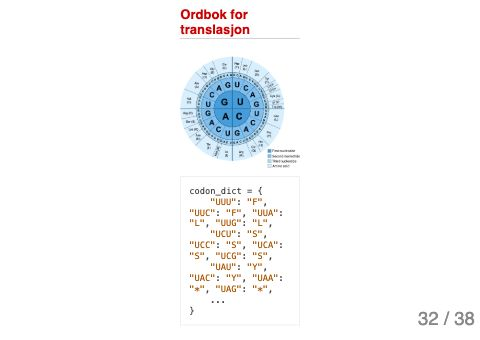

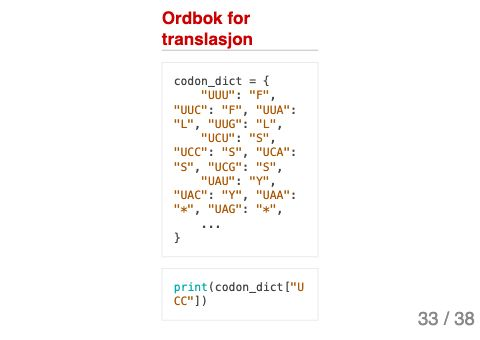

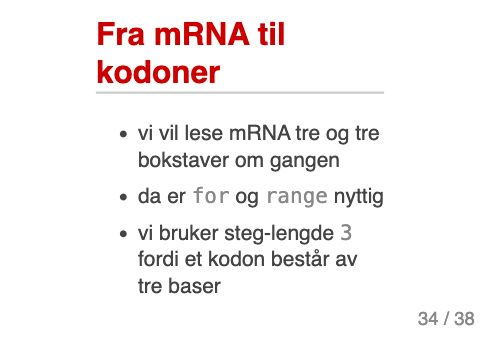

</div>

Da kan vi sette alt sammen og lage en enkel modell av translasjon:

In [25]:
mrna = "AUGGCUUAA"
protein = ""

for i in range(0, len(mrna), 3):
    kodon = mrna[i:i+3]
    aminosyre = codon_dict[kodon]
    protein = protein + aminosyre

print(protein)

MA*


<div class="alert alert-block alert-info">
Spør studentene før programmet kjøres:
Hva tror dere blir skrevet ut?
Pek på <code>protein = protein + aminosyre</code>
og be dem forklare hva som bygges opp.
</div>

Men hva skjer om mRNA sekvensen ikke er et multippel av tre baser,
for eksempel har en ekstra "C": "AUGGCUUAAC"?

In [26]:
mrna = "AUGGCUUAAC"
protein = ""

for i in range(0, len(mrna), 3):
    kodon = mrna[i:i+3]
    aminosyre = codon_dict[kodon]
    protein = protein + aminosyre

print(protein)

KeyError: 'C'

<div class="alert alert-block alert-info">
La studentene diskutere hvorfor vi fikk denne feilmeldingen.
</div>

I slike tilfeller er det lurt å legge inn en ekstra sjekk.
Da kan vi bruke *nestede if-setninger*:

In [27]:
mrna = "AUGGCUUAA"
protein = ""

for i in range(0, len(mrna), 3):
    kodon = mrna[i:i+3]
    if len(kodon) == 3:
        if kodon in codon_dict:
            aminosyre = codon_dict[kodon]
            protein = protein + aminosyre

print(protein)

MA*


Her ser vi to nivåer av innrykk:
* først sjekker vi om vi faktisk har et kodon med tre bokstaver
* deretter sjekker vi om kodonet finnes i ordboken

Den samme logikken kan vi også skrive med `and`:

In [28]:
mrna = "AUGGCUUAA"
protein = ""

for i in range(0, len(mrna), 3):
    kodon = mrna[i:i+3]
    if len(kodon) == 3 and kodon in codon_dict:
        aminosyre = codon_dict[kodon]
        protein = protein + aminosyre

print(protein)

MA*


Når begge delene må være sanne, kan vi bruke `and`.

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* `and`, `or`
* Snarveier for regneoperasjoner

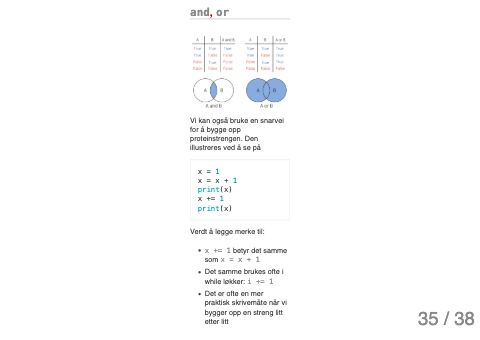

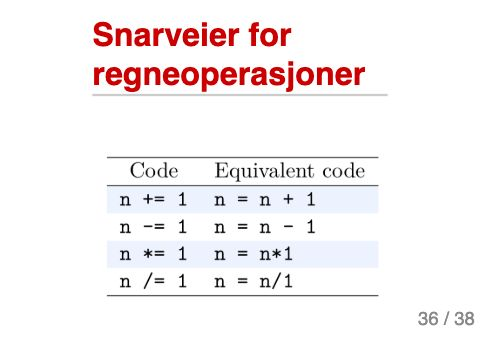

</div>

Vårt program for translasjon blir da:

In [29]:
mrna = "AUGGCUUAA"
protein = ""

for i in range(0, len(mrna), 3):
    kodon = mrna[i:i+3]
    if len(kodon) == 3 and kodon in codon_dict:
        aminosyre = codon_dict[kodon]
        protein += aminosyre

print(protein)

MA*


Her betyr `protein += aminosyre` altså
det samme som `protein = protein + aminosyre`.

Da har vi et ferdig program:

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* DNA til protein i et program

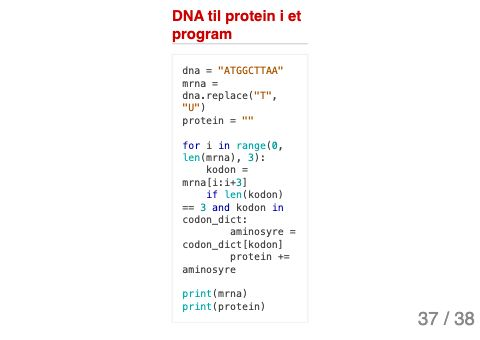

</div>

Nå kan vi oppsummere mini-prosjektet vårt:

In [30]:
dna = "ATGGCTTAA"
mrna = dna.replace("T", "U")
protein = ""

for i in range(0, len(mrna), 3):
    kodon = mrna[i:i+3]
    if len(kodon) == 3 and kodon in codon_dict:
        aminosyre = codon_dict[kodon]
        protein += aminosyre

print(f"mRNA: {mrna}")
print(f"Protein: {protein}")

mRNA: AUGGCUUAA
Protein: MA*


Neste vi bør gjøre er å lage funksjoner som gjør de biologiske stegene:

In [31]:
# transcribe function
def transkripsjon(dna):

    # kode som gjøre transkripsjon

    return rna

# translate function
def translasjon(mRNA):

    # kode som gjør translasjon
    return protein

Det gjør vi ikke nå men gjøres i læreboken.

En siste ting er at vårt program ikke helt tar hensyn til biologien ennå.
Translasjon starter på første forekomt av AUG, og slutter ved første stoppkodon.
Hvis vi tester en lengre sekvens som denne:

In [32]:
dna = "AGCTAGAGCAATGCGGATTAAAACGATCGGCTAACC"
mrna = dna.replace("T", "U")
protein = ""

for i in range(0, len(mrna), 3):
    kodon = mrna[i:i+3]
    if len(kodon) == 3 and kodon in codon_dict:
        aminosyre = codon_dict[kodon]
        protein += aminosyre

print(f"mRNA: {mrna}")
print(f"Protein: {protein}")

mRNA: AGCUAGAGCAAUGCGGAUUAAAACGAUCGGCUAACC
Protein: S*SNAD*NDRLT


Løsningen for dette er å faktisk bruke en while løkke. 
Se koden i læreboken for det.
<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* Oppgave: positive heltall

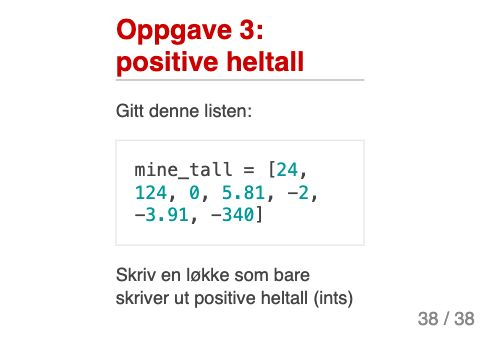

</div>

<div class="alert alert-block alert-info">
Hvs det er tid til over: hvis hvordan man gjør om koden til to funskjoner,
en for transkripsjon og en for translasjon.
</div>